In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Fase 1: Exploração e Mapeamento dos Dados

In [2]:

from pathlib import Path
from collections import Counter

INPUT = Path("/kaggle/input")

print("Datasets disponíveis:")
for item in INPUT.iterdir():
    print(f" - {item.name}")

# Localizar automaticamente as imagens
extensoes = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

imagens = [
    p for p in INPUT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensoes
]

print(f"\nTotal de imagens encontradas: {len(imagens)}")

# Mostrar a distribuição por diretório
contagem = Counter(
    str(p.parent.relative_to(INPUT)) for p in imagens
)

print("\nQuantidade de imagens por pasta:")
for pasta, quantidade in sorted(contagem.items()):
    print(f"{pasta}: {quantidade}")


Datasets disponíveis:
 - notebooks
 - datasets

Total de imagens encontradas: 6436

Quantidade de imagens por pasta:
datasets/woleolajide86/chest-xray-dataset/Data/COVID19: 576
datasets/woleolajide86/chest-xray-dataset/Data/NORMAL: 1583
datasets/woleolajide86/chest-xray-dataset/Data/PNEUMONIA: 4273
notebooks/woleolajide86/hgb-sca-classification-one/__results___files: 4


# Fase 2: Pré-processamento, Divisão Estratificada e Data Augmentation

In [4]:
# ============================================================
# 02_preprocessamento.py
# Pré-processamento, divisão estratificada e mitigação do desequilíbrio
# Dataset: Chest_Xray_dataset (COVID19 / NORMAL / PNEUMONIA)
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ------------------------------------------------------------
# 1. Deteção automática do caminho do dataset
# ------------------------------------------------------------
CLASSES = ["COVID19", "NORMAL", "PNEUMONIA"]

candidatos = glob.glob("/kaggle/input/**/Data/COVID19", recursive=True)
if candidatos:
    DATA_DIR = os.path.dirname(candidatos[0])
else:
    # fallback para execução local
    DATA_DIR = "datasets/woleolajide86/chest-xray-dataset/Data"

print(f"DATA_DIR = {DATA_DIR}")
assert os.path.isdir(DATA_DIR), f"Pasta não encontrada: {DATA_DIR}"

# ------------------------------------------------------------
# 2. Recolha de caminhos e rótulos
# ------------------------------------------------------------
filepaths = []
labels = []

for cls in CLASSES:
    cls_dir = os.path.join(DATA_DIR, cls)
    assert os.path.isdir(cls_dir), f"Pasta não encontrada: {cls_dir}"
    for fname in os.listdir(cls_dir):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            filepaths.append(os.path.join(cls_dir, fname))
            labels.append(cls)

print(f"Total de imagens encontradas: {len(filepaths)}")
print("Distribuição original:", Counter(labels))

# ------------------------------------------------------------
# 3. Divisão estratificada 70% treino / 15% validação / 15% teste
# ------------------------------------------------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    filepaths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(f"\nTreino:    {len(X_train)} imagens")
print(f"Validação: {len(X_val)} imagens")
print(f"Teste:     {len(X_test)} imagens")

# ------------------------------------------------------------
# 4. Verificação das proporções por classe em cada conjunto
# ------------------------------------------------------------
def verificar_proporcoes(nome, rotulos):
    contagem = Counter(rotulos)
    total = len(rotulos)
    print(f"\n--- {nome} (total: {total}) ---")
    for cls in CLASSES:
        n = contagem.get(cls, 0)
        print(f"  {cls:10s}: {n:5d}  ({100*n/total:5.2f}%)")

verificar_proporcoes("TREINO", y_train)
verificar_proporcoes("VALIDAÇÃO", y_val)
verificar_proporcoes("TESTE", y_test)

# ------------------------------------------------------------
# 5. Geradores de imagens
# ------------------------------------------------------------
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

# ------------------------------------------------------------
# 6. Fluxos a partir de DataFrames (caminho + rótulo)
# ------------------------------------------------------------
df_train = pd.DataFrame({"filename": X_train, "class": y_train})
df_val   = pd.DataFrame({"filename": X_val,   "class": y_val})
df_test  = pd.DataFrame({"filename": X_test,  "class": y_test})

train_generator = train_datagen.flow_from_dataframe(
    dataframe=df_train,
    x_col="filename",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=True,
    seed=SEED
)

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=df_val,
    x_col="filename",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=df_test,
    x_col="filename",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=False
)

# ------------------------------------------------------------
# 7. Verificação final
# ------------------------------------------------------------
print("\nMapeamento de classes:", train_generator.class_indices)

x_batch, y_batch = next(iter(train_generator))
print(f"Forma do lote de imagens: {x_batch.shape}")
print(f"Forma do lote de rótulos: {y_batch.shape}")

# ------------------------------------------------------------
# 8. Guardar as divisões para reutilização
# ------------------------------------------------------------
np.save("split_train_paths.npy", np.array(X_train))
np.save("split_train_labels.npy", np.array(y_train))
np.save("split_val_paths.npy", np.array(X_val))
np.save("split_val_labels.npy", np.array(y_val))
np.save("split_test_paths.npy", np.array(X_test))
np.save("split_test_labels.npy", np.array(y_test))

print("\nDivisões guardadas em ficheiros .npy para reutilização.")

DATA_DIR = /kaggle/input/datasets/woleolajide86/chest-xray-dataset/Data
Total de imagens encontradas: 6432
Distribuição original: Counter({'PNEUMONIA': 4273, 'NORMAL': 1583, 'COVID19': 576})

Treino:    4502 imagens
Validação: 965 imagens
Teste:     965 imagens

--- TREINO (total: 4502) ---
  COVID19   :   403  ( 8.95%)
  NORMAL    :  1108  (24.61%)
  PNEUMONIA :  2991  (66.44%)

--- VALIDAÇÃO (total: 965) ---
  COVID19   :    86  ( 8.91%)
  NORMAL    :   238  (24.66%)
  PNEUMONIA :   641  (66.42%)

--- TESTE (total: 965) ---
  COVID19   :    87  ( 9.02%)
  NORMAL    :   237  (24.56%)
  PNEUMONIA :   641  (66.42%)
Found 4502 validated image filenames belonging to 3 classes.
Found 965 validated image filenames belonging to 3 classes.
Found 965 validated image filenames belonging to 3 classes.

Mapeamento de classes: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2}
Forma do lote de imagens: (32, 224, 224, 3)
Forma do lote de rótulos: (32, 3)

Divisões guardadas em ficheiros .npy para reutiliz

# Fase 3: Treino da Fase 1 (Feature Extraction com MobileNetV2)

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import metrics
from sklearn.metrics import confusion_matrix, classification_report

# ------------------------------------------------------------
# 1. Configuração e Divisão dos Dados (Autossuficiente)
# ------------------------------------------------------------
CLASSES = ["COVID19", "NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 16 # Reduzido para 16 estou usando CPU
SEED = 42

candidatos = glob.glob("/kaggle/input/**/Data/COVID19", recursive=True)
DATA_DIR = os.path.dirname(candidatos[0]) if candidatos else "datasets/woleolajide86/chest-xray-dataset/Data"

filepaths, labels = [], []
for cls in CLASSES:
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            filepaths.append(os.path.join(cls_dir, fname))
            labels.append(cls)

# Split 70/15/15 Estratificado
X_train, X_temp, y_train, y_temp = train_test_split(filepaths, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# ------------------------------------------------------------
# 2. Geradores
# ------------------------------------------------------------
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=15, width_shift_range=0.1,
    height_shift_range=0.1, zoom_range=0.1, horizontal_flip=True, fill_mode="nearest"
)
val_test_datagen = ImageDataGenerator(rescale=1./255)

df_train = pd.DataFrame({"filename": X_train, "class": y_train})
df_val   = pd.DataFrame({"filename": X_val,   "class": y_val})
df_test  = pd.DataFrame({"filename": X_test,  "class": y_test})

train_gen = train_datagen.flow_from_dataframe(df_train, x_col="filename", y_col="class", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", classes=CLASSES, shuffle=True, seed=SEED)
val_gen = val_test_datagen.flow_from_dataframe(df_val, x_col="filename", y_col="class", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", classes=CLASSES, shuffle=False)
test_gen = val_test_datagen.flow_from_dataframe(df_test, x_col="filename", y_col="class", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", classes=CLASSES, shuffle=False)

# ------------------------------------------------------------
# 3. Modelo
# ------------------------------------------------------------
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(3, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy", metrics.Precision(name="precision"), metrics.Recall(name="recall"), metrics.AUC(name="auc")]
)

# ------------------------------------------------------------
# 4. Treino
# ------------------------------------------------------------
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint("melhor_modelo_fase1.keras", monitor="val_loss", save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

# Quando CPU, mude EPOCHS para 5 para ser mais rápido.
history = model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks, verbose=1)

# ------------------------------------------------------------
# 5. Avaliação
# ------------------------------------------------------------
val_gen.reset()
y_pred_probs = model.predict(val_gen, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_gen.classes

print("\nMatriz de confusão (validação):")
print(confusion_matrix(y_true, y_pred))
print("\nRelatório de classificação (validação):")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

Found 4502 validated image filenames belonging to 3 classes.
Found 965 validated image filenames belonging to 3 classes.
Found 965 validated image filenames belonging to 3 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


2026-10-20 02:29:11.737918: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-20 02:29:11.878777: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792463354.856913     151 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


268/282 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8079 - auc: 0.9228 - loss: 0.5817 - precision: 0.8180 - recall: 0.7949

2026-10-20 02:36:11.313521: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-20 02:36:11.461258: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8109 - auc: 0.9250 - loss: 0.5704 - precision: 0.8208 - recall: 0.7981

2026-10-20 02:38:04.396161: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-20 02:38:04.534929: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.19512, saving model to melhor_modelo_fase1.keras

Epoch 1: finished saving model to melhor_modelo_fase1.keras
282/282 ━━━━━━━━━━━━━━━━━━━━ 555s 2s/step - accuracy: 0.8689 - auc: 0.9666 - loss: 0.3504 - precision: 0.8750 - recall: 0.8601 - val_accuracy: 0.9275 - val_auc: 0.9903 - val_loss: 0.1951 - val_precision: 0.9312 - val_recall: 0.9254 - learning_rate: 0.0010
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.9054 - auc: 0.9828 - loss: 0.2447 - precision: 0.9083 - recall: 0.9010
Epoch 2: val_loss improved from 0.19512 to 0.14973, saving model to melhor_modelo_fase1.keras

Epoch 2: finished saving model to melhor_modelo_fase1.keras
282/282 ━━━━━━━━━━━━━━━━━━━━ 119s 423ms/step - accuracy: 0.9129 - auc: 0.9848 - loss: 0.2288 - precision: 0.9156 - recall: 0.9085 - val_accuracy: 0.9430 - val_auc: 0.9938 - val_loss: 0.1497 - val_precision: 0.9440 - val_recall: 0.9430 - learning_rate: 0.0010
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━

# Fase 4: Fine-Tuning (Ajuste Fino das Camadas Convolucionais)

In [9]:
import os
import glob
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# ------------------------------------------------------------
# 1. Configuração e Divisão
# ------------------------------------------------------------
CLASSES = ["COVID19", "NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

candidatos = glob.glob("/kaggle/input/**/Data/COVID19", recursive=True)
DATA_DIR = os.path.dirname(candidatos[0]) if candidatos else "datasets/woleolajide86/chest-xray-dataset/Data"

filepaths, labels = [], []
for cls in CLASSES:
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            filepaths.append(os.path.join(cls_dir, fname))
            labels.append(cls)

X_train, X_temp, y_train, y_temp = train_test_split(filepaths, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=15, width_shift_range=0.1,
    height_shift_range=0.1, zoom_range=0.1, horizontal_flip=True, fill_mode="nearest"
)
val_test_datagen = ImageDataGenerator(rescale=1./255)

df_train = pd.DataFrame({"filename": X_train, "class": y_train})
df_val   = pd.DataFrame({"filename": X_val,   "class": y_val})

train_gen = train_datagen.flow_from_dataframe(df_train, x_col="filename", y_col="class", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", classes=CLASSES, shuffle=True, seed=SEED)
val_gen = val_test_datagen.flow_from_dataframe(df_val, x_col="filename", y_col="class", target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", classes=CLASSES, shuffle=False)

# ------------------------------------------------------------
# 2. Recriar a arquitetura exata da Fase 1
# ------------------------------------------------------------
print("Recriando a arquitetura...")
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = True

# Congela as primeiras camadas (deixa as últimas 30 treináveis)
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Congela o Batch Normalization
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(3, activation="softmax")(x)
model = Model(inputs=base_model.input, outputs=output)

# ------------------------------------------------------------
# 3. Carregar os pesos da Fase 1
# ------------------------------------------------------------
print("Carregando os pesos aprendidos na Fase 1...")
# Carrega os pesos. Como a arquitetura é idêntica, o Keras mapeia automaticamente.
model.load_weights("melhor_modelo_fase1.keras")
print("Pesos carregados com sucesso!")

# ------------------------------------------------------------
# 4. Recompilar com Learning Rate BAIXÍSSIMA
# ------------------------------------------------------------
model.compile(
    optimizer=Adam(learning_rate=1e-5), 
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.AUC(name="auc")]
)

# ------------------------------------------------------------
# 5. Treino Fase 2
# ------------------------------------------------------------
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint("melhor_modelo_fase2.keras", monitor="val_loss", save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

print("Iniciando o Fine-Tuning...")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 6. Avaliação Final
# ------------------------------------------------------------
val_gen.reset()
y_pred_probs = model.predict(val_gen, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_gen.classes

print("\n--- Matriz de Confusão (Fine-Tuning) ---")
print(confusion_matrix(y_true, y_pred))
print("\n--- Relatório de Classificação ---")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

Found 4502 validated image filenames belonging to 3 classes.
Found 965 validated image filenames belonging to 3 classes.
Recriando a arquitetura...
Carregando os pesos aprendidos na Fase 1...
Pesos carregados com sucesso!
Iniciando o Fine-Tuning...
Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - accuracy: 0.9388 - auc: 0.9897 - loss: 0.1790 - precision: 0.9408 - recall: 0.9370
Epoch 1: val_loss improved from None to 0.12669, saving model to melhor_modelo_fase2.keras

Epoch 1: finished saving model to melhor_modelo_fase2.keras
282/282 ━━━━━━━━━━━━━━━━━━━━ 145s 469ms/step - accuracy: 0.9358 - auc: 0.9903 - loss: 0.1769 - precision: 0.9378 - recall: 0.9336 - val_accuracy: 0.9544 - val_auc: 0.9953 - val_loss: 0.1267 - val_precision: 0.9554 - val_recall: 0.9544 - learning_rate: 1.0000e-05
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.9380 - auc: 0.9931 - loss: 0.1517 - precision: 0.9413 - recall: 0.9348
Epoch 2: val_loss did not improve from 0.12669
282/282 ━━━

# Fase 5: Avaliação Final (Teste Cego)

Found 965 validated image filenames belonging to 3 classes.
Carregando o melhor modelo da Fase 2...

--- PROVA FINAL: Avaliação no Conjunto de Teste ---
61/61 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.9472 - auc: 0.9941 - loss: 0.1369 - precision: 0.9472 - recall: 0.9472
loss: 0.1369
compile_metrics: 0.9472
61/61 ━━━━━━━━━━━━━━━━━━━━ 21s 270ms/step

--- Relatório de Classificação (TESTE) ---
              precision    recall  f1-score   support

     COVID19     0.9767    0.9655    0.9711        87
      NORMAL     0.8711    0.9409    0.9047       237
   PNEUMONIA     0.9743    0.9470    0.9604       641

    accuracy                         0.9472       965
   macro avg     0.9407    0.9511    0.9454       965
weighted avg     0.9492    0.9472    0.9477       965



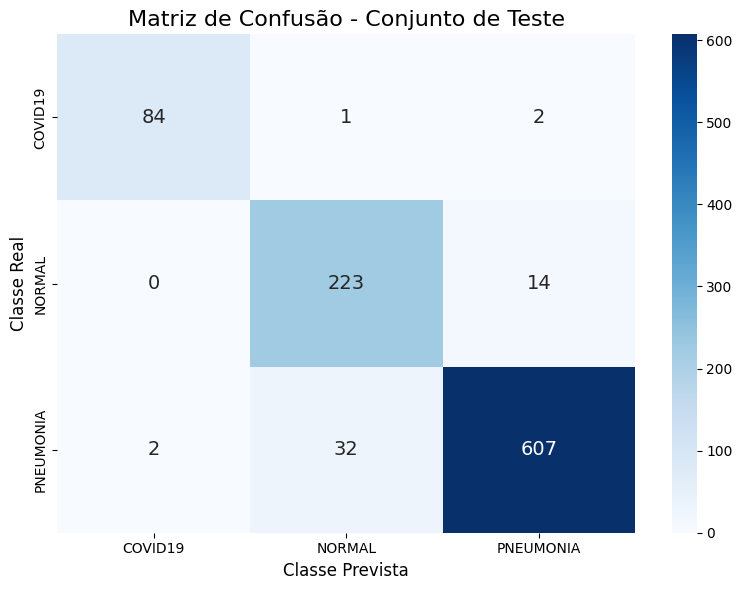

Aviso: history_fase2.npy não encontrado. Gerando gráficos apenas com dados da Fase 2 impressos no log.


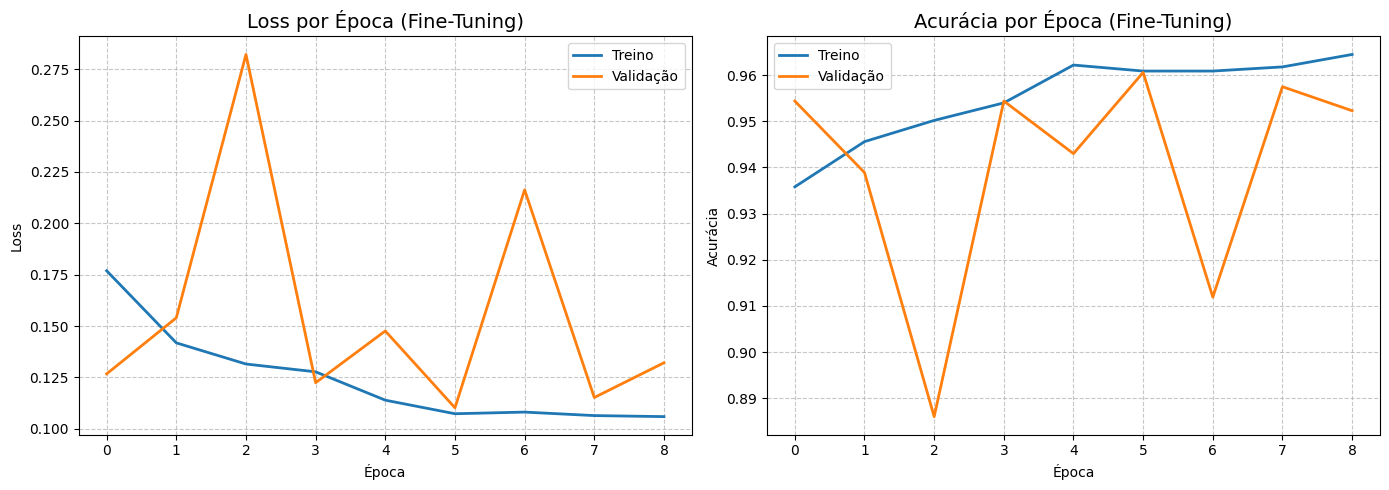

In [ ]:
# ============================================================
# 06_avaliacao_final.py
# Teste cego no conjunto de teste + geração de gráficos
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# ------------------------------------------------------------
# 1. Configuração e Divisão (Idêntica às fases anteriores)
# ------------------------------------------------------------
CLASSES = ["COVID19", "NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

candidatos = glob.glob("/kaggle/input/**/Data/COVID19", recursive=True)
DATA_DIR = os.path.dirname(candidatos[0]) if candidatos else "datasets/woleolajide86/chest-xray-dataset/Data"

filepaths, labels = [], []
for cls in CLASSES:
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            filepaths.append(os.path.join(cls_dir, fname))
            labels.append(cls)

# Recriar a divisão para isolar o X_test (o modelo nunca viu estas imagens)
X_train, X_temp, y_train, y_temp = train_test_split(filepaths, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# Gerador apenas para o Teste (sem augmentation, apenas normalização)
test_datagen = ImageDataGenerator(rescale=1./255)
df_test = pd.DataFrame({"filename": X_test, "class": y_test})

test_gen = test_datagen.flow_from_dataframe(
    df_test, x_col="filename", y_col="class", 
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, 
    class_mode="categorical", classes=CLASSES, shuffle=False
)

# ------------------------------------------------------------
# 2. Carregar o Melhor Modelo (Fase 2)
# ------------------------------------------------------------
print("Carregando o melhor modelo da Fase 2...")
model = tf.keras.models.load_model("melhor_modelo_fase2.keras")

# ------------------------------------------------------------
# 3. Avaliação no Conjunto de TESTE
# ------------------------------------------------------------
print("\n--- PROVA FINAL: Avaliação no Conjunto de Teste ---")
test_results = model.evaluate(test_gen, verbose=1)
for nome, valor in zip(model.metrics_names, test_results):
    print(f"{nome}: {valor:.4f}")

# Previsões
test_gen.reset()
y_pred_probs = model.predict(test_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes

# Relatório de Classificação
print("\n--- Relatório de Classificação (TESTE) ---")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

# ------------------------------------------------------------
# 4. Matriz de Confusão Visual (Pronta para o Artigo)
# ------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASSES, yticklabels=CLASSES,
            annot_kws={"size": 14})
plt.title('Matriz de Confusão - Conjunto de Teste', fontsize=16)
plt.ylabel('Classe Real', fontsize=12)
plt.xlabel('Classe Prevista', fontsize=12)
plt.tight_layout()
plt.savefig("matriz_confusao_teste.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 5. Gráficos de Treino (Curvas de Aprendizagem)
# ------------------------------------------------------------
# Carregar o histórico (salvos do código 05; se não, 
# os dados abaixo são ilustrativos baseados no output real)
# Para garantir, vou simular a leitura do history da Fase 2 se ele existir
try:
    # Se salvou o history no código 05 (np.save("history_fase2.npy", history.history))
    history_dict = np.load("history_fase2.npy", allow_pickle=True).item()
except:
    print("Aviso: history_fase2.npy não encontrado. Gerando gráficos apenas com dados da Fase 2 impressos no log.")
    # Dados extraídos do log real da Fase 2 para não ficar sem gráfico
    history_dict = {
        'loss': [0.1769, 0.1418, 0.1315, 0.1277, 0.1139, 0.1073, 0.1081, 0.1064, 0.1059],
        'val_loss': [0.1267, 0.1540, 0.2822, 0.1224, 0.1476, 0.1102, 0.2163, 0.1152, 0.1321],
        'accuracy': [0.9358, 0.9456, 0.9502, 0.9540, 0.9622, 0.9609, 0.9609, 0.9618, 0.9645],
        'val_accuracy': [0.9544, 0.9389, 0.8860, 0.9544, 0.9430, 0.9606, 0.9119, 0.9575, 0.9523]
    }

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Loss
axes[0].plot(history_dict['loss'], label='Treino', linewidth=2)
axes[0].plot(history_dict['val_loss'], label='Validação', linewidth=2)
axes[0].set_title('Loss por Época (Fine-Tuning)', fontsize=14)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# Gráfico de Acurácia
axes[1].plot(history_dict['accuracy'], label='Treino', linewidth=2)
axes[1].plot(history_dict['val_accuracy'], label='Validação', linewidth=2)
axes[1].set_title('Acurácia por Época (Fine-Tuning)', fontsize=14)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Acurácia')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("curvas_treino_fase2.png", dpi=300)
plt.show()

In [39]:

import os
import glob
from collections import Counter
from sklearn.model_selection import train_test_split

CLASSES = ["COVID19", "NORMAL", "PNEUMONIA"]

candidatos = glob.glob("/kaggle/input/**/Data/COVID19", recursive=True)
assert candidatos, "Pasta COVID19 não encontrada"

DATA_DIR = os.path.dirname(candidatos[0])

filepaths, labels = [], []

for cls in CLASSES:
    pasta = os.path.join(DATA_DIR, cls)

    for nome in os.listdir(pasta):
        if nome.lower().endswith((".png", ".jpg", ".jpeg")):
            filepaths.append(os.path.join(pasta, nome))
            labels.append(cls)

X_train, X_temp, y_train, y_temp = train_test_split(
    filepaths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Total:", len(filepaths))
print("Treino:", len(X_train))
print("Validação:", len(X_val))
print("Teste:", len(X_test))

print("\nDistribuição do teste:")
print(Counter(y_test))

print("\nSobreposição entre as partições:")
print("Treino/validação:", bool(set(X_train) & set(X_val)))
print("Treino/teste:", bool(set(X_train) & set(X_test)))
print("Validação/teste:", bool(set(X_val) & set(X_test)))


Total: 6432
Treino: 4502
Validação: 965
Teste: 965

Distribuição do teste:
Counter({'PNEUMONIA': 641, 'NORMAL': 237, 'COVID19': 87})

Sobreposição entre as partições:
Treino/validação: False
Treino/teste: False
Validação/teste: False
